# SUSPrev SC — Análise Preditiva de Procedimentos Cirúrgicos Eletivos em Santa Catarina

Projeto SCTEC. Variável-alvo: contagem mensal do indicador operacional de procedimentos cirúrgicos eletivos obtido da tabela `procedimentos_sp`. A contagem representa combinações distintas AIH/procedimento/CNES, não uma contagem auditada de atos cirúrgicos individuais. Histórico: janeiro/2019 a agosto/2026.

## Configuração do ambiente

Nesta etapa, o notebook identifica automaticamente a raiz do projeto
SUSPrev SC e configura o caminho necessário para importar os módulos
Python desenvolvidos na pasta `src`.

Essa configuração permite executar o notebook a partir da pasta
`notebooks`, mantendo a organização modular do projeto.

In [39]:
import sys  # Permite configurar os caminhos de importação do Python
from pathlib import Path  # Permite manipular caminhos de forma independente do sistema operacional

RAIZ_PROJETO = Path.cwd().resolve()  # Identifica o diretório atual

# Localiza a raiz do projeto a partir da pasta src.
while not (RAIZ_PROJETO / "src").is_dir():
    if RAIZ_PROJETO == RAIZ_PROJETO.parent:
        raise FileNotFoundError(
            "Não foi possível localizar a raiz do projeto SUSPrev SC."
        )
    RAIZ_PROJETO = RAIZ_PROJETO.parent

# Permite importar os módulos Python do projeto.
if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))

# Define os caminhos utilizados nas próximas etapas.
CAMINHO_BANCO = RAIZ_PROJETO / "data" / "processed" / "susprev_sc.db"
PASTA_MODELOS = RAIZ_PROJETO / "models"
PASTA_RESULTADOS = RAIZ_PROJETO / "outputs"

# Confirma a existência do banco antes de iniciar a análise.
if not CAMINHO_BANCO.is_file():
    raise FileNotFoundError(f"Banco de dados não encontrado: {CAMINHO_BANCO}")

print("Raiz do projeto:", RAIZ_PROJETO)
print("Banco de dados:", CAMINHO_BANCO)
print("Ambiente configurado com sucesso!")


Raiz do projeto: C:\Users\crisj\OneDrive\Área de Trabalho\SCTECH\susprev-sc
Banco de dados: C:\Users\crisj\OneDrive\Área de Trabalho\SCTECH\susprev-sc\data\processed\susprev_sc.db
Ambiente configurado com sucesso!


In [40]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Importação das bibliotecas

As bibliotecas são importadas de forma centralizada para manter
o notebook organizado e facilitar a reprodução dos experimentos.

Serão utilizadas ferramentas para manipulação de dados,
visualização, pré-processamento, treinamento, avaliação,
comparação e serialização de modelos de regressão.

In [55]:
# ============================================================
# SUSPrev SC — Verificação e instalação de dependências
# ============================================================

import importlib.util
import subprocess
import sys

# Relaciona os nomes dos módulos aos pacotes de instalação.
DEPENDENCIAS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "xgboost": "xgboost",
    "joblib": "joblib",
}

# Identifica somente as bibliotecas ausentes.
pacotes_ausentes = [
    pacote
    for modulo, pacote in DEPENDENCIAS.items()
    if importlib.util.find_spec(modulo) is None
]

if pacotes_ausentes:
    print("Instalando bibliotecas ausentes:", ", ".join(pacotes_ausentes))

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        *pacotes_ausentes,
    ])

    importlib.invalidate_caches()
    print("Instalação concluída!")
else:
    print("Todas as dependências já estão instaladas.")


Todas as dependências já estão instaladas.


## Fase 1 — Preparação e serialização do modelo (pipeline offline)

### 1.1 Carregamento e validação dos dados

Os registros da tabela `procedimentos_sp` são agregados por competência para formar a série temporal mensal utilizada em todas as etapas seguintes.

In [56]:
# Indicador SP: procedimentos cirúrgicos eletivos, agregado por competência.
import sqlite3
import pandas as pd

with sqlite3.connect(CAMINHO_BANCO) as conexao:
    df = pd.read_sql_query("""
        SELECT ano, mes, SUM(quantidade) AS quantidade
        FROM procedimentos_sp
        GROUP BY ano, mes
        ORDER BY ano, mes
    """, conexao)

if df.empty:
    raise ValueError("A tabela procedimentos_sp não possui registros.")
print(f"Competências carregadas: {len(df)}")
display(df.head())

Competências carregadas: 92


,ano,mes,quantidade
0,2019,1,5835
1,2019,2,6874
2,2019,3,6972
3,2019,4,7550
4,2019,5,8416


In [57]:
# Conferência dos dados de entrada.
print("Estrutura do DataFrame:")
df.info()
print("\nValores ausentes por coluna:")
display(df.isna().sum().to_frame("Valores ausentes"))
assert df[["ano", "mes", "quantidade"]].notna().all().all(), "Há valores ausentes nos dados mensais."
assert (df["quantidade"] >= 0).all(), "Foram encontradas quantidades negativas."

Estrutura do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   ano         92 non-null     int64
 1   mes         92 non-null     int64
 2   quantidade  92 non-null     int64
dtypes: int64(3)
memory usage: 2.3 KB

Valores ausentes por coluna:


,Valores ausentes
ano,0
mes,0
quantidade,0


In [58]:
# Cobertura e continuidade mensal.
competencias = df[["ano", "mes"]].drop_duplicates().sort_values(["ano", "mes"])
competencias_data = pd.to_datetime(dict(year=competencias.ano, month=competencias.mes, day=1))
periodos_esperados = pd.period_range("2019-01", "2026-08", freq="M")
periodos_encontrados = pd.PeriodIndex(competencias_data, freq="M")
assert periodos_encontrados.equals(periodos_esperados), "Competências ausentes, duplicadas ou fora do período 2019-01 a 2026-08."
print("Cobertura validada:", periodos_encontrados.min(), "a", periodos_encontrados.max())
print("Total do indicador SP:", int(df.quantidade.sum()))

Cobertura validada: 2019-01 a 2026-08
Total do indicador SP: 971479


### 1.2 Análise exploratória (EDA)

#### 1.2.1 Evolução mensal dos procedimentos cirúrgicos eletivos

O indicador SP é agregado por competência e representado em uma série temporal.

Meses analisados: 92


,ano,mes,quantidade,data
0,2019,1,5835,2019-01-01
1,2019,2,6874,2019-02-01
2,2019,3,6972,2019-03-01
3,2019,4,7550,2019-04-01
4,2019,5,8416,2019-05-01


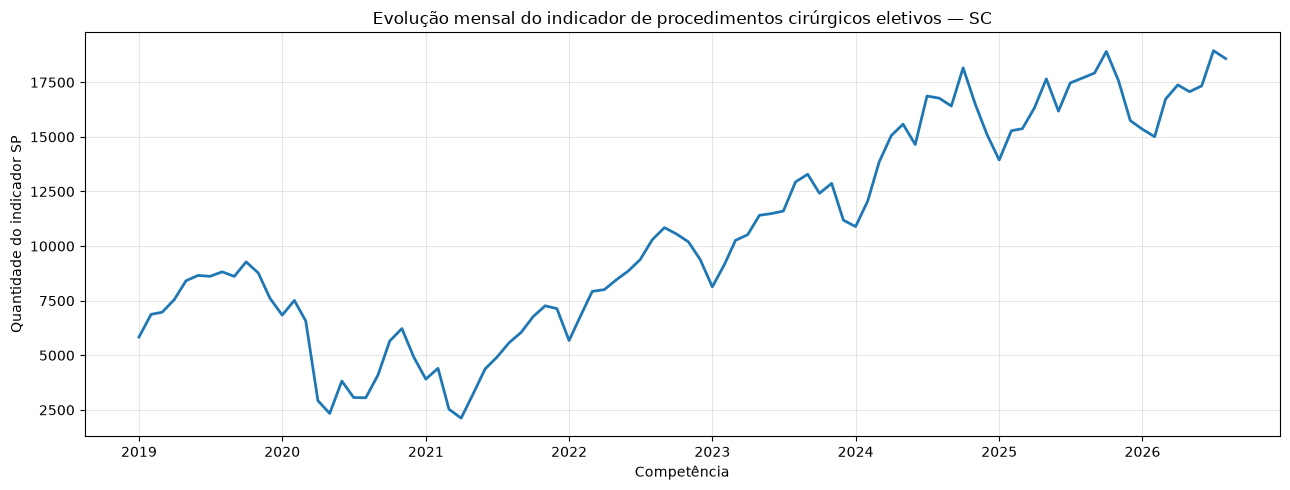

In [59]:
# Série mensal de procedimentos cirúrgicos eletivos (SP).
import matplotlib.pyplot as plt
serie_mensal = df.groupby(["ano", "mes"], as_index=False)["quantidade"].sum()
serie_mensal["data"] = pd.to_datetime(dict(year=serie_mensal.ano, month=serie_mensal.mes, day=1))
serie_mensal = serie_mensal.sort_values("data").reset_index(drop=True)
(PASTA_RESULTADOS / "reports").mkdir(parents=True, exist_ok=True)
(PASTA_RESULTADOS / "figures").mkdir(parents=True, exist_ok=True)
serie_mensal.to_csv(PASTA_RESULTADOS / "reports" / "01_evolucao_mensal_procedimentos_sp.csv", index=False, encoding="utf-8-sig")
print("Meses analisados:", len(serie_mensal))
display(serie_mensal.head())
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(serie_mensal["data"], serie_mensal["quantidade"], linewidth=2)
ax.set_title("Evolução mensal do indicador de procedimentos cirúrgicos eletivos — SC")
ax.set_xlabel("Competência")
ax.set_ylabel("Quantidade do indicador SP")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "figures" / "01_evolucao_mensal_procedimentos_sp.png", dpi=300, bbox_inches="tight")
plt.show()

### 1.2.2 Estatísticas descritivas da série temporal

Resumo da distribuição mensal do indicador de procedimentos cirúrgicos eletivos.

In [60]:
# Calcula as estatísticas descritivas da série mensal de internações.
estatisticas = serie_mensal["quantidade"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

estatisticas.index = [
    "Meses analisados",
    "Média mensal",
    "Mediana mensal",
    "Desvio-padrão",
    "Mínimo mensal",
    "Máximo mensal",
]

display(estatisticas.to_frame(name="Valor").round(2))

# Salva as estatísticas na estrutura existente do projeto.
estatisticas.to_frame(name="Valor").round(2).to_csv(
    PASTA_RESULTADOS / "reports" / "02_estatisticas_descritivas.csv",
    encoding="utf-8-sig",
)

print("Estatísticas descritivas salvas em outputs/reports/")

,Valor
Meses analisados,92.00
Média mensal,10559.55
Mediana mensal,9792.50
Desvio-padrão,4883.98
Mínimo mensal,2124.00
Máximo mensal,18946.00


Estatísticas descritivas salvas em outputs/reports/


### 1.2.3 Distribuição mensal do indicador SP

Histograma da quantidade mensal de procedimentos cirúrgicos eletivos.

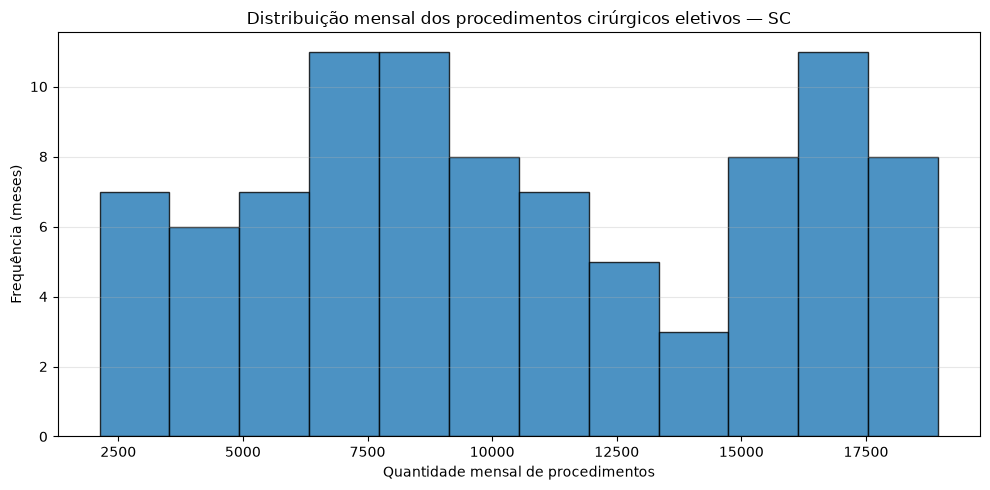

In [61]:
# Distribuição mensal das procedimentos cirúrgicos eletivos.
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    serie_mensal["quantidade"],
    bins=12,
    edgecolor="black",
    alpha=0.8,
)

ax.set_title("Distribuição mensal dos procedimentos cirúrgicos eletivos — SC")
ax.set_xlabel("Quantidade mensal de procedimentos")
ax.set_ylabel("Frequência (meses)")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(
    PASTA_RESULTADOS / "figures" / "02_distribuicao_mensal_procedimentos_sp.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

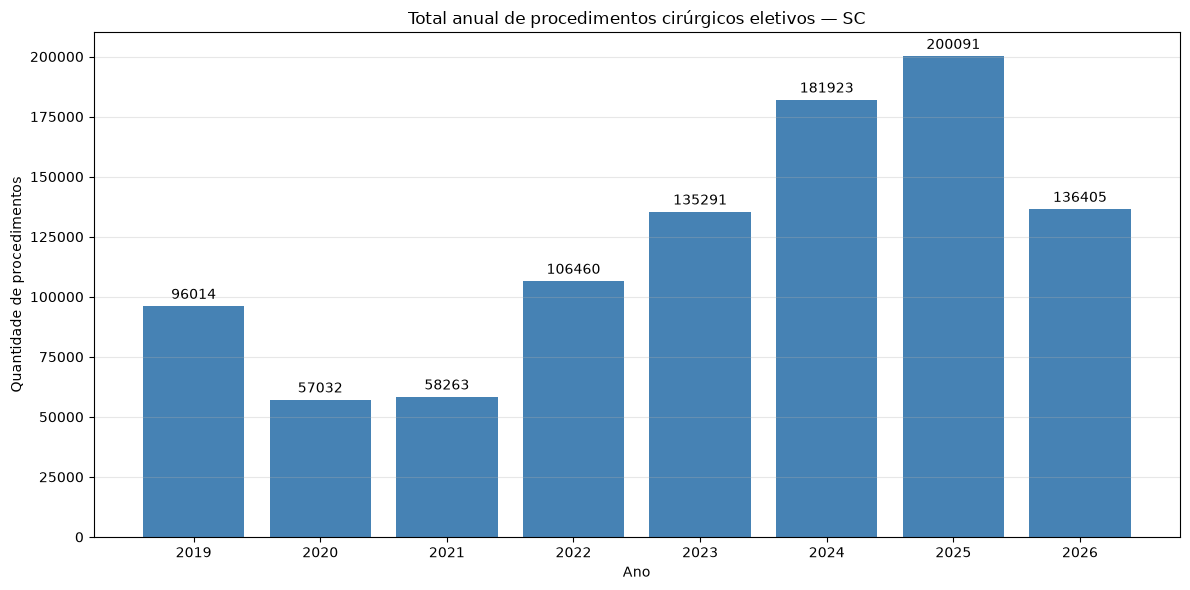

In [62]:
# Distribuição anual dos procedimentos cirúrgicos eletivos — SC

procedimentos_ano = (
    serie_mensal.groupby("ano")["quantidade"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))

barras = plt.bar(
    procedimentos_ano["ano"].astype(str),
    procedimentos_ano["quantidade"],
    color="steelblue"
)

plt.bar_label(barras, fmt="%.0f", padding=3)

plt.title("Total anual de procedimentos cirúrgicos eletivos — SC")
plt.xlabel("Ano")
plt.ylabel("Quantidade de procedimentos")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

caminho_grafico = PASTA_RESULTADOS / "figures" / "procedimentos_cirurgicos_por_ano.png"
caminho_grafico.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(caminho_grafico, dpi=300, bbox_inches="tight")
plt.show()

## 1.3 — Série temporal e variável-alvo

A variável-alvo é a **quantidade mensal do indicador de procedimentos cirúrgicos eletivos**, proveniente da tabela `procedimentos_sp`. Os atributos do mês previsto serão derivados exclusivamente de meses anteriores. A série possui 92 competências, de janeiro/2019 a agosto/2026.

In [63]:
# Reutiliza a série SP validada na EDA.
import numpy as np
serie_sp = serie_mensal.copy()
assert len(serie_sp) == 92
print("Cobertura:", serie_sp.data.min().date(), "até", serie_sp.data.max().date())
print("Total SP:", int(serie_sp.quantidade.sum()))
display(serie_sp.tail())

Cobertura: 2019-01-01 até 2026-08-01
Total SP: 971479


,ano,mes,quantidade,data
87,2026,4,17379,2026-04-01
88,2026,5,17070,2026-05-01
89,2026,6,17336,2026-06-01
90,2026,7,18946,2026-07-01
91,2026,8,18585,2026-08-01


### 1.4 — Atributos temporais, separação cronológica e comparação de três algoritmos

**Modelos combinados:** Regressão Linear, Random Forest e XGBoost. O baseline ingênuo (último mês) é apresentado **separadamente**, como referência de desempenho, e não substitui os três algoritmos. Os lags de 1, 2, 3, 6 e 12 meses e a média móvel de três meses usam somente o passado. A escolha utiliza MAE na validação; o teste permanece isolado.

In [64]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import joblib

base = serie_sp.copy()
for lag in (1, 2, 3, 6, 12):
    base[f"lag_{lag}"] = base["quantidade"].shift(lag)
base["media_3"] = base["quantidade"].shift(1).rolling(3).mean()
base["mes_sin"] = np.sin(2 * np.pi * base["mes"] / 12)
base["mes_cos"] = np.cos(2 * np.pi * base["mes"] / 12)
atributos = ["lag_1", "lag_2", "lag_3", "lag_6", "lag_12", "media_3", "mes_sin", "mes_cos"]
base = base.dropna(subset=atributos).reset_index(drop=True)
assert len(base) == 80, "Esperadas 80 observações após 12 meses de lags."
treino, validacao, teste = base.iloc[:-24].copy(), base.iloc[-24:-12].copy(), base.iloc[-12:].copy()
assert treino.data.max() < validacao.data.min() < teste.data.min()
for nome, parte in [("Treino", treino), ("Validação", validacao), ("Teste", teste)]:
    print(f"{nome}: {parte.data.min().date()} a {parte.data.max().date()} ({len(parte)} meses)")

def metricas(y, pred):
    return {
        "MAE": float(mean_absolute_error(y, pred)),
        "MSE": float(mean_squared_error(y, pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y, pred))),
        "R2": float(r2_score(y, pred)),
    }

modelos = {
    "regressao_linear": Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
        ("modelo", LinearRegression()),
    ]),
    "random_forest": Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("modelo", RandomForestRegressor(
            n_estimators=200, max_depth=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        )),
    ]),
    "xgboost": Pipeline([
        ("imputacao", SimpleImputer(strategy="median")),
        ("modelo", XGBRegressor(
            n_estimators=200, max_depth=3, learning_rate=0.05,
            subsample=0.9, colsample_bytree=0.9,
            objective="reg:squarederror", random_state=42, n_jobs=2,
        )),
    ]),
}

resultados_val = {"baseline_ultimo_mes": metricas(validacao.quantidade, validacao.lag_1)}
for nome, modelo in modelos.items():
    modelo.fit(treino[atributos], treino["quantidade"])
    resultados_val[nome] = metricas(validacao.quantidade, modelo.predict(validacao[atributos]))

comparacao_validacao = pd.DataFrame(resultados_val).T.sort_values("MAE")
print("Comparação na VALIDAÇÃO (baseline + três algoritmos):")

nomes_modelos = {
    "xgboost": "XGBoost",
    "random_forest": "Random Forest",
    "regressao_linear": "Regressão Linear",
    "baseline_ultimo_mes": "Baseline (último mês)"
}

tabela_validacao = comparacao_validacao.rename(
    index=nomes_modelos
)

tabela_exibicao = tabela_validacao.copy()

for coluna in ["MAE", "MSE", "RMSE"]:
    casas = 0 if coluna == "MSE" else 2
    tabela_exibicao[coluna] = tabela_exibicao[coluna].map(
        lambda valor: f"{valor:,.{casas}f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )

tabela_exibicao["R2"] = tabela_exibicao["R2"].map(
    lambda valor: f"{valor:.3f}".replace(".", ",")
)

print("Comparação dos modelos — Validação (set/2024 a ago/2025)")
display(tabela_exibicao)
melhor = min(modelos, key=lambda nome: resultados_val[nome]["MAE"])
print("Algoritmo selecionado pelo menor MAE na validação:", melhor)

Treino: 2020-01-01 a 2024-08-01 (56 meses)
Validação: 2024-09-01 a 2025-08-01 (12 meses)
Teste: 2025-09-01 a 2026-08-01 (12 meses)
Comparação na VALIDAÇÃO (baseline + três algoritmos):
Comparação dos modelos — Validação (set/2024 a ago/2025)


,MAE,MSE,RMSE,R2
XGBoost,"893,06",1.090.420,"1.044,23","0,254"
Random Forest,"1.033,24",1.622.480,"1.273,77","-0,110"
Baseline (último mês),"1.085,83",1.467.502,"1.211,41","-0,004"
Regressão Linear,"1.136,27",1.607.511,"1.267,88","-0,100"


Algoritmo selecionado pelo menor MAE na validação: xgboost


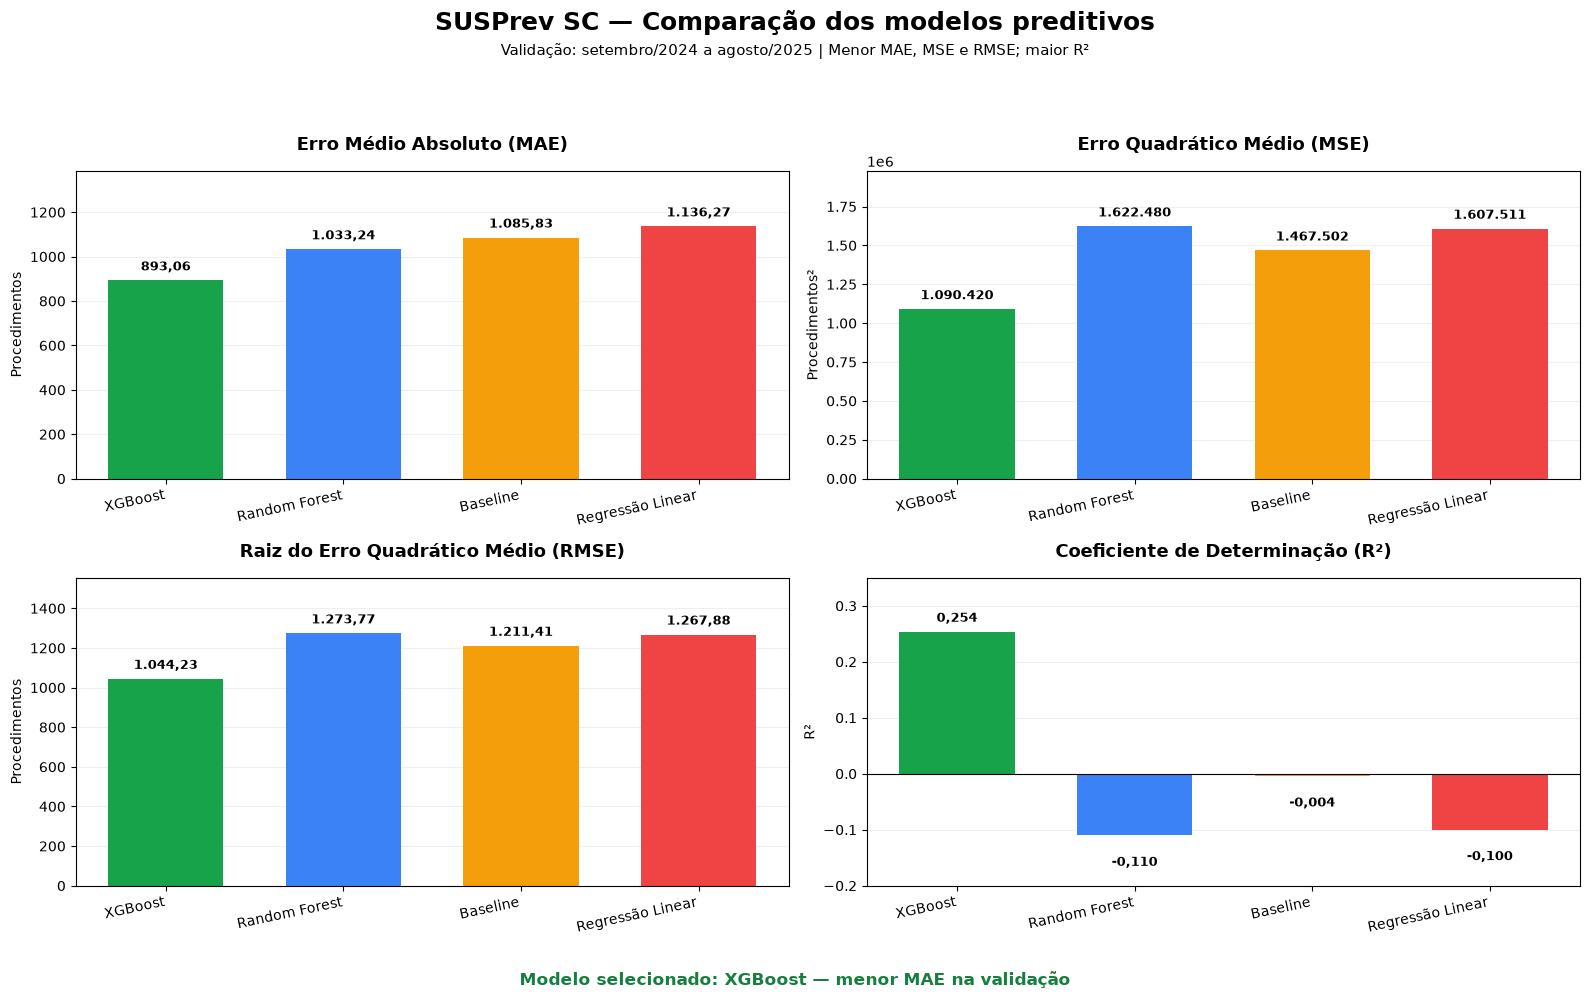

In [65]:
# 1.4 — Comparação gráfica dos modelos na validação

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Utiliza as métricas já calculadas na célula anterior
dados = comparacao_validacao.rename(index={
    "xgboost": "XGBoost",
    "random_forest": "Random Forest",
    "regressao_linear": "Regressão Linear",
    "baseline_ultimo_mes": "Baseline"
}).loc[["XGBoost", "Random Forest", "Baseline", "Regressão Linear"]]

cores = ["#16A34A", "#3B82F6", "#F59E0B", "#EF4444"]

fig, eixos = plt.subplots(2, 2, figsize=(16, 10))

configuracoes = [
    ("MAE", "Erro Médio Absoluto (MAE)", "Procedimentos"),
    ("MSE", "Erro Quadrático Médio (MSE)", "Procedimentos²"),
    ("RMSE", "Raiz do Erro Quadrático Médio (RMSE)", "Procedimentos"),
    ("R2", "Coeficiente de Determinação (R²)", "R²")
]

for ax, (metrica, titulo, unidade) in zip(eixos.flat, configuracoes):

    valores = dados[metrica].to_numpy()
    posicoes = np.arange(len(dados))

    barras = ax.bar(
        posicoes,
        valores,
        color=cores,
        width=0.65
    )

    ax.set_title(titulo, fontsize=13, fontweight="bold", pad=15)
    ax.set_ylabel(unidade)
    ax.set_xticks(posicoes)
    ax.set_xticklabels(dados.index, rotation=12, ha="right")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    if metrica == "R2":
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_ylim(min(-0.2, valores.min() * 1.5),
                    max(0.35, valores.max() * 1.3))
    else:
        ax.set_ylim(0, valores.max() * 1.22)

    # Rótulos legíveis em formato brasileiro
    for barra, valor in zip(barras, valores):
        if metrica == "MSE":
            rotulo = f"{valor:,.0f}"
        elif metrica == "R2":
            rotulo = f"{valor:.3f}"
        else:
            rotulo = f"{valor:,.2f}"

        rotulo = rotulo.replace(",", "X").replace(".", ",").replace("X", ".")

        deslocamento = 5 if valor >= 0 else -15

        ax.annotate(
            rotulo,
            (barra.get_x() + barra.get_width() / 2, valor),
            xytext=(0, deslocamento),
            textcoords="offset points",
            ha="center",
            va="bottom" if valor >= 0 else "top",
            fontsize=9,
            fontweight="bold"
        )

fig.suptitle(
    "SUSPrev SC — Comparação dos modelos preditivos",
    fontsize=18,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.945,
    "Validação: setembro/2024 a agosto/2025 | "
    "Menor MAE, MSE e RMSE; maior R²",
    ha="center",
    fontsize=11
)

fig.text(
    0.5, 0.015,
    "Modelo selecionado: XGBoost — menor MAE na validação",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="#15803D"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.92])

# Salva na pasta de gráficos do projeto
caminho_grafico = PASTA_RESULTADOS / "figures" / "comparacao_modelos_validacao.png"
caminho_grafico.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(caminho_grafico, dpi=300, bbox_inches="tight")
plt.show()

### 1.5 — Avaliação final, relatório de métricas e serialização

O algoritmo escolhido **entre os três modelos** é reajustado em treino + validação e avaliado **uma única vez** no teste cronológico. Depois, uma cópia do mesmo algoritmo é treinada em todos os meses disponíveis para uso na API. O relatório registra a validação, o teste e a comparação com o baseline. O artefato `models/susprev_sp.joblib` contém o pipeline completo de pré-processamento e modelo.

In [66]:
# ============================================================
# 1.5 — AVALIAÇÃO FINAL, RELATÓRIO DE MÉTRICAS E SERIALIZAÇÃO
# SUSPrev SC
# ============================================================

from sklearn.base import clone
import joblib
import pandas as pd

# ------------------------------------------------------------
# 1. Avaliação final no conjunto de teste
# ------------------------------------------------------------
# O algoritmo foi escolhido na validação (seção 1.4).
# O teste não participa da seleção nem do ajuste de parâmetros.

treino_validacao = pd.concat(
    [treino, validacao],
    ignore_index=True
)

modelo_avaliado = clone(modelos[melhor])

modelo_avaliado.fit(
    treino_validacao[atributos],
    treino_validacao["quantidade"]
)

pred_teste = modelo_avaliado.predict(teste[atributos])

resultado_teste = metricas(
    teste["quantidade"],
    pred_teste
)

resultado_baseline_teste = metricas(
    teste["quantidade"],
    teste["lag_1"]
)


PASTA_MODELOS.mkdir(parents=True, exist_ok=True)

PASTA_METRICAS = PASTA_RESULTADOS / "metrics"
PASTA_METRICAS.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 3. Comparação final: modelo selecionado x baseline
# ------------------------------------------------------------

nomes_modelos = {
    "xgboost": "XGBoost",
    "random_forest": "Random Forest",
    "regressao_linear": "Regressão Linear"
}

nome_modelo = nomes_modelos[melhor]

# Tabela numérica: preserva os valores para análises posteriores.
comparacao_teste = pd.DataFrame({
    "Modelo": [
        nome_modelo,
        "Baseline (último mês)"
    ],
    "MAE": [
        resultado_teste["MAE"],
        resultado_baseline_teste["MAE"]
    ],
    "MSE": [
        resultado_teste["MSE"],
        resultado_baseline_teste["MSE"]
    ],
    "RMSE": [
        resultado_teste["RMSE"],
        resultado_baseline_teste["RMSE"]
    ],
    "R2": [
        resultado_teste["R2"],
        resultado_baseline_teste["R2"]
    ]
})

# Salva a tabela numérica.
comparacao_teste.to_csv(
    PASTA_METRICAS / "teste_final.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 4. Formatação 
# ------------------------------------------------------------

def formatar_numero(valor, casas=2):
    return (
        f"{valor:,.{casas}f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )


tabela_teste = comparacao_teste.rename(
    columns={"R2": "R²"}
).copy()

for coluna in ["MAE", "RMSE"]:
    tabela_teste[coluna] = tabela_teste[coluna].map(
        lambda valor: formatar_numero(valor, 2)
    )

tabela_teste["MSE"] = tabela_teste["MSE"].map(
    lambda valor: formatar_numero(valor, 0)
)

tabela_teste["R²"] = tabela_teste["R²"].map(
    lambda valor: formatar_numero(valor, 3)
)

print("=" * 65)
print("SUSPrev SC — AVALIAÇÃO FINAL")
print("=" * 65)
print("Período de teste: setembro/2025 a agosto/2026")
print(f"Modelo selecionado na validação: {nome_modelo}")
print()
print("COMPARAÇÃO DAS MÉTRICAS NO TESTE")

display(tabela_teste.set_index("Modelo"))

tabela_teste.to_csv(
    PASTA_METRICAS / "comparacao_teste_formatada.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 5. Relatório de validação dos três algoritmos e baseline
# ------------------------------------------------------------

comparacao_validacao.rename_axis(
    "modelo"
).reset_index().to_csv(
    PASTA_METRICAS / "validacao_tres_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 6. Relatório com valores reais e previstos no teste
# ------------------------------------------------------------

previsoes_teste = pd.DataFrame({
    "data": teste["data"].to_numpy(),
    "real": teste["quantidade"].to_numpy(),
    "previsto": pred_teste,
    "baseline_ultimo_mes": teste["lag_1"].to_numpy()
})

previsoes_teste.to_csv(
    PASTA_METRICAS / "previsoes_teste_sp.csv",
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 7. Treinamento definitivo para utilização na API
# ------------------------------------------------------------
# Após a avaliação, o algoritmo selecionado é treinado
# com todos os meses disponíveis para modelagem.

modelo_final = clone(modelos[melhor])

modelo_final.fit(
    base[atributos],
    base["quantidade"]
)


# ------------------------------------------------------------
# 8. Preparação do artefato
# ------------------------------------------------------------

artefato = {
    "modelo": modelo_final,
    "estrategia": melhor,
    "atributos": atributos,
    "alvo": "procedimentos_cirurgicos_eletivos_sp",
    "definicao_alvo": (
        "contagem mensal de combinações distintas "
        "AIH/procedimento/CNES"
    ),
    "horizonte_meses": 1,
    "ultima_competencia": str(
        serie_sp["data"].max().date()
    ),
    "historico_quantidade": (
        serie_sp["quantidade"]
        .astype(int)
        .tail(12)
        .tolist()
    ),
    "metricas_validacao": resultados_val[melhor],
    "metricas_teste": resultado_teste,
    "metricas_baseline_teste": resultado_baseline_teste,
}


# ------------------------------------------------------------
# 9. Serialização do modelo
# ------------------------------------------------------------

caminho_artefato = PASTA_MODELOS / "susprev_sp.joblib"

joblib.dump(
    artefato,
    caminho_artefato
)


# ------------------------------------------------------------
# 10. Verificação do artefato salvo
# ------------------------------------------------------------

artefato_verificado = joblib.load(caminho_artefato)

previsao_verificacao = artefato_verificado["modelo"].predict(
    base[atributos].tail(1)
)

assert len(previsao_verificacao) == 1


# ------------------------------------------------------------
# 11. Resumo final da execução
# ------------------------------------------------------------

print()
print("=" * 65)
print("ARQUIVOS GERADOS")
print("=" * 65)

print(f"Modelo: {caminho_artefato}")
print(f"Relatórios: {PASTA_METRICAS}")
print()
print("✓ Validação dos três algoritmos registrada")
print("✓ Métricas do teste final registradas")
print("✓ Tabela formatada salva")
print("✓ Previsões do teste salvas")
print("✓ Modelo serializado e verificado")


SUSPrev SC — AVALIAÇÃO FINAL
Período de teste: setembro/2025 a agosto/2026
Modelo selecionado na validação: XGBoost

COMPARAÇÃO DAS MÉTRICAS NO TESTE


,MAE,MSE,RMSE,R²
Modelo,,,,
XGBoost,"842,37",870.986,"933,27","0,455"
Baseline (último mês),"836,25",1.058.881,"1.029,02","0,338"



ARQUIVOS GERADOS
Modelo: C:\Users\crisj\OneDrive\Área de Trabalho\SCTECH\susprev-sc\models\susprev_sp.joblib
Relatórios: C:\Users\crisj\OneDrive\Área de Trabalho\SCTECH\susprev-sc\outputs\metrics

✓ Validação dos três algoritmos registrada
✓ Métricas do teste final registradas
✓ Tabela formatada salva
✓ Previsões do teste salvas
✓ Modelo serializado e verificado


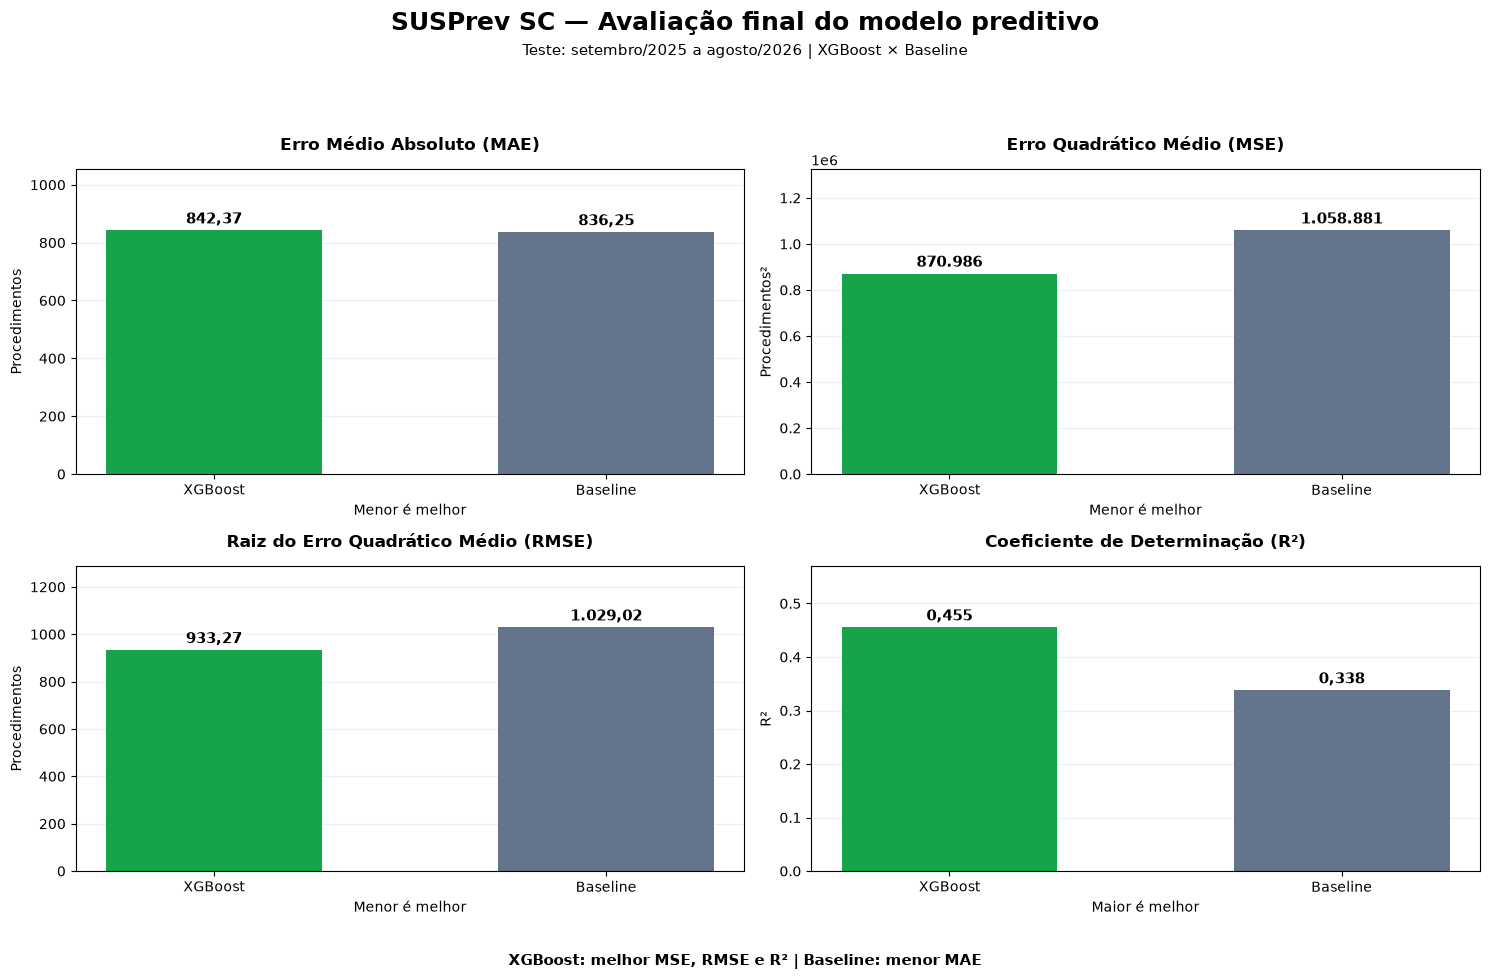

In [68]:
# 1.5 — Comparação gráfica dos resultados do teste final

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

metricas_grafico = [
    ("MAE", "Erro Médio Absoluto (MAE)", "Menor é melhor"),
    ("MSE", "Erro Quadrático Médio (MSE)", "Menor é melhor"),
    ("RMSE", "Raiz do Erro Quadrático Médio (RMSE)", "Menor é melhor"),
    ("R2", "Coeficiente de Determinação (R²)", "Maior é melhor")
]

fig, eixos = plt.subplots(2, 2, figsize=(15, 10))

cores = ["#16A34A", "#64748B"]
nomes = ["XGBoost", "Baseline"]

def numero_br(valor, casas=2):
    return (
        f"{valor:,.{casas}f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )

for ax, (metrica, titulo, criterio) in zip(
    eixos.flat, metricas_grafico
):
    valores = [
        resultado_teste[metrica],
        resultado_baseline_teste[metrica]
    ]

    barras = ax.bar(
        nomes,
        valores,
        color=cores,
        width=0.55
    )

    ax.set_title(titulo, fontsize=12, fontweight="bold", pad=14)
    ax.set_xlabel(criterio, fontsize=10)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.set_ylim(0, max(valores) * 1.25)

    if metrica == "MSE":
        ax.set_ylabel("Procedimentos²")
        casas = 0
    elif metrica == "R2":
        ax.set_ylabel("R²")
        casas = 3
    else:
        ax.set_ylabel("Procedimentos")
        casas = 2

    for barra, valor in zip(barras, valores):
        ax.annotate(
            numero_br(valor, casas),
            (
                barra.get_x() + barra.get_width() / 2,
                barra.get_height()
            ),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=11,
            fontweight="bold"
        )

fig.suptitle(
    "SUSPrev SC — Avaliação final do modelo preditivo",
    fontsize=18,
    fontweight="bold"
)

fig.text(
    0.5, 0.935,
    "Teste: setembro/2025 a agosto/2026 | XGBoost × Baseline",
    ha="center",
    fontsize=11
)

fig.text(
    0.5, 0.025,
    "XGBoost: melhor MSE, RMSE e R² | "
    "Baseline: menor MAE",
    ha="center",
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.91])

# Salvar na pasta de gráficos do projeto
caminho_grafico = (
    PASTA_RESULTADOS / "figures"
    / "comparacao_teste_final.png"
)

caminho_grafico.parent.mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    caminho_grafico,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [69]:
import joblib

artefato = joblib.load(PASTA_MODELOS / "susprev_sp.joblib")

print("Conteúdo do arquivo:")
print(artefato.keys())

Conteúdo do arquivo:
dict_keys(['modelo', 'estrategia', 'atributos', 'alvo', 'definicao_alvo', 'horizonte_meses', 'ultima_competencia', 'historico_quantidade', 'metricas_validacao', 'metricas_teste', 'metricas_baseline_teste'])
